# Creating a summary of the updated Hallmark pathway gene sets across the DC cells
# 13-10-2026
Ovarian cancer samples only
* dataframes made previously (2026-04-10_PseudobulkingSampleType_fromNRcode.jpynb), separate for each DC subset and each has seperate metadata file
* Following code from ChatGPT
* Looking at primary vs mets only
* Flip the colours so that up in primary is red here. That means reformat  obs_df = obs_df[
        obs_df["sample_type_major2"].isin(
            ["primary tumour", "metastatic tumour"]  --> "metastatic tumour", "primary tumour"
        )
    ]
* Subset Hallmark and KEGG gene sets to only the ones suggested by KT in meeting on 10/09/26
* Add the Hallmark cholesterol homeostasis, g2m checkpoint and angiogensis hallmark pathways suggested by KR

In [2]:
#load packages 
import os
import tools

In [3]:
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns
import numpy as np

In [4]:
import scanpy as sc
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

In [5]:
#show current directory 
os.getcwd()
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment'

### Read in the full DC dataset
20250617_AllDC_bbknn.h5ad which is the DC only version of atlas


In [6]:
data_all = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad')

In [7]:
data_all

AnnData object with n_obs × n_vars = 29887 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions'

### Create 3 separate anndata objects with the DC subsets

In [8]:
#isolate ovarian cancer data
data_oc = data_all[data_all.obs["cancer_with_H"] == "HGSOC"]
data_oc

View of AnnData object with n_obs × n_vars = 9188 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispe

In [9]:
#isolate primacy and met data too
data_oc = data_oc[data_oc.obs["sample_type_major2"].isin(["metastatic tumour", "primary tumour"])].copy()

In [10]:
data_DC1 = data_oc[data_oc.obs["NR_annotations_simple"] == "cDC1"]
data_DC2 = data_oc[data_oc.obs["NR_annotations_simple"] == "cDC2"]
data_mregDC = data_oc[data_oc.obs["NR_annotations_simple"] == "mregDC"]

In [11]:
cell_type_data = {
    "DC1": data_DC1,
    "DC2": data_DC2,
    "mregDC": data_mregDC
}

### Import Hallmark gene pathways

In [12]:
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwaySets')
H_sets = pd.read_excel("hallmark_sets.xlsx", sheet_name=None)

In [13]:
# Change keys to be gene set name (the first value in the 'gs_name' column) instead of Sheet1 etc 
H_sets2 = {df["gs_name"].iloc[0]: df for _, df in H_sets.items()}
H_sets = H_sets2

# Result
print(H_sets.keys())

dict_keys(['HALLMARK_ADIPOGENESIS', 'HALLMARK_ALLOGRAFT_REJECTION', 'HALLMARK_ANDROGEN_RESPONSE', 'HALLMARK_ANGIOGENESIS', 'HALLMARK_APICAL_JUNCTION', 'HALLMARK_APICAL_SURFACE', 'HALLMARK_APOPTOSIS', 'HALLMARK_BILE_ACID_METABOLISM', 'HALLMARK_CHOLESTEROL_HOMEOSTASIS', 'HALLMARK_COAGULATION', 'HALLMARK_COMPLEMENT', 'HALLMARK_DNA_REPAIR', 'HALLMARK_E2F_TARGETS', 'HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION', 'HALLMARK_ESTROGEN_RESPONSE_EARLY', 'HALLMARK_ESTROGEN_RESPONSE_LATE', 'HALLMARK_FATTY_ACID_METABOLISM', 'HALLMARK_G2M_CHECKPOINT', 'HALLMARK_GLYCOLYSIS', 'HALLMARK_HEDGEHOG_SIGNALING', 'HALLMARK_HEME_METABOLISM', 'HALLMARK_HYPOXIA', 'HALLMARK_IL2_STAT5_SIGNALING', 'HALLMARK_IL6_JAK_STAT3_SIGNALING', 'HALLMARK_INFLAMMATORY_RESPONSE', 'HALLMARK_INTERFERON_ALPHA_RESPONSE', 'HALLMARK_INTERFERON_GAMMA_RESPONSE', 'HALLMARK_KRAS_SIGNALING_DN', 'HALLMARK_KRAS_SIGNALING_UP', 'HALLMARK_MITOTIC_SPINDLE', 'HALLMARK_MTORC1_SIGNALING', 'HALLMARK_MYC_TARGETS_V1', 'HALLMARK_MYC_TARGETS_V2', 'HALLMAR

Subset to only include pathways of interest

In [14]:
keys_include = [
"HALLMARK_COMPLEMENT",
"HALLMARK_GLYCOLYSIS",
"HALLMARK_HYPOXIA",
"HALLMARK_IL2_STAT5_SIGNALING",
"HALLMARK_IL6_JAK_STAT3_SIGNALING",
"HALLMARK_INFLAMMATORY_RESPONSE",
"HALLMARK_INTERFERON_ALPHA_RESPONSE",
"HALLMARK_INTERFERON_GAMMA_RESPONSE",
"HALLMARK_OXIDATIVE_PHOSPHORYLATION",
"HALLMARK_TGF_BETA_SIGNALING",
"HALLMARK_TNFA_SIGNALING_VIA_NFKB",
"HALLMARK_ANGIOGENESIS",
"HALLMARK_G2M_CHECKPOINT",
"HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION",
"HALLMARK_CHOLESTEROL_HOMEOSTASIS"
]

In [15]:
# create a new dictionary with select keys (pathway sets)
H_sets_sub = {key: H_sets[key] for key in keys_include if key in H_sets}

# Display the new dictionary
H_sets_sub

{'HALLMARK_COMPLEMENT':     gene_symbol  ncbi_gene     ensembl_gene db_gene_symbol  db_ncbi_gene  \
 0         ACTN2         88  ENSG00000077522          ACTN2            88   
 1         ADAM9       8754  ENSG00000168615          ADAM9          8754   
 2        ADRA2B        151  ENSG00000274286         ADRA2B           151   
 3        AKAP10      11216  ENSG00000108599         AKAP10         11216   
 4           ANG        283  ENSG00000214274            ANG           283   
 ..          ...        ...              ...            ...           ...   
 195      VCPIP1      80124  ENSG00000175073         VCPIP1         80124   
 196         WAS       7454  ENSG00000015285            WAS          7454   
 197     XPNPEP1       7511  ENSG00000108039        XPNPEP1          7511   
 198        ZEB1       6935  ENSG00000148516           ZEB1          6935   
 199       ZFPM2      23414  ENSG00000169946          ZFPM2         23414   
 
      db_ensembl_gene source_gene  gs_id           

Score each DC subset according to the Hallmark gene sets

In [16]:
# Iterate through each gene set in H_sets_sub - DC1
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_DC1, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets_sub - DC2
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_DC2, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets_sub - mregDC
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_mregDC, gene_list=gene_set, score_name=f"{set_name}_score")

       'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'NOL3', 'PFKFB1', 'PGLS', 'RARS1'],
      dtype='object')
       'GAPDHS', 'IGFBP1', 'INHA', 'KIF5A', 'LALBA', 'LARGE1', 'NCAN', 'NOCT',
       'PCK1', 'PKLR', 'PPARGC1A', 'PPP1R3C', 'STBD1'],
      dtype='object')
       'OPRK1', 'ROS1', 'SELENOS', 'SLC28A2', 'TACR3', 'VIP'],
      dtype='object')


/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:163: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


       'ATP5MC2', 'ATP5MC3', 'ATP5ME', 'ATP5MF', 'ATP5MG', 'ATP5PB', 'ATP5PD',
       'ATP5PF', 'ATP5PO', 'TOMM70'],
      dtype='object')
       'MAP3K20', 'NSD2', 'PRP4K', 'PTTG3P', 'TENT4A', 'TGFB1'],
      dtype='object')
       'P3H1', 'POSTN', 'PRSS2', 'SCG2', 'SGCG', 'TGFB1'],
      dtype='object')
       'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'NOL3', 'PFKFB1', 'PGLS', 'RARS1'],
      dtype='object')
       'GAPDHS', 'IGFBP1', 'INHA', 'KIF5A', 'LALBA', 'LARGE1', 'NCAN', 'NOCT',
       'PCK1', 'PKLR', 'PPARGC1A', 'PPP1R3C', 'STBD1'],
      dtype='object')


/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:163: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


       'OPRK1', 'ROS1', 'SELENOS', 'SLC28A2', 'TACR3', 'VIP'],
      dtype='object')
       'ATP5MC2', 'ATP5MC3', 'ATP5ME', 'ATP5MF', 'ATP5MG', 'ATP5PB', 'ATP5PD',
       'ATP5PF', 'ATP5PO', 'TOMM70'],
      dtype='object')
       'MAP3K20', 'NSD2', 'PRP4K', 'PTTG3P', 'TENT4A', 'TGFB1'],
      dtype='object')
       'P3H1', 'POSTN', 'PRSS2', 'SCG2', 'SGCG', 'TGFB1'],
      dtype='object')
       'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'NOL3', 'PFKFB1', 'PGLS', 'RARS1'],
      dtype='object')
       'GAPDHS', 'IGFBP1', 'INHA', 'KIF5A', 'LALBA', 'LARGE1', 'NCAN', 'NOCT',
       'PCK1', 'PKLR', 'PPARGC1A', 'PPP1R3C', 'STBD1'],
      dtype='object')
       'OPRK1', 'ROS1', 'SELENOS', 'SLC28A2', 'TACR3', 'VIP'],
      dtype='object')


/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:163: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


       'ATP5MC2', 'ATP5MC3', 'ATP5ME', 'ATP5MF', 'ATP5MG', 'ATP5PB', 'ATP5PD',
       'ATP5PF', 'ATP5PO', 'TOMM70'],
      dtype='object')
       'MAP3K20', 'NSD2', 'PRP4K', 'PTTG3P', 'TENT4A', 'TGFB1'],
      dtype='object')
       'P3H1', 'POSTN', 'PRSS2', 'SCG2', 'SGCG', 'TGFB1'],
      dtype='object')


# Run Hallmark pathway

In [17]:
results = []

for cell_type, adata in cell_type_data.items():

    obs_df = adata.obs.copy()

    # Keep only metastatic and primary
    obs_df = obs_df[
        obs_df["sample_type_major2"].isin(
            [ "metastatic tumour", "primary tumour"]
        )
    ]

    for gene_set in H_sets_sub.keys():

        score_col = f"{gene_set}_score"

        if score_col not in obs_df.columns:
            continue

        # Remove missing values
        data = obs_df[
            ["sample_type_major2", score_col]
        ].dropna()

        metastatic = data.loc[
        data["sample_type_major2"] == "metastatic tumour",
        score_col
        ]
        
        primary = data.loc[
        data["sample_type_major2"] == "primary tumour",
        score_col
        ]

        if len(metastatic) == 0 or len(primary) == 0:
            continue

        # Welch t-test
        stat, p_value = ttest_ind(
            metastatic,
            primary,
            equal_var=False
        )

        mean_metastatic = metastatic.mean()
        mean_primary = primary.mean()

        results.append({
            "Cell Type": cell_type,
            "Gene Set": gene_set,
            "Metastatic Mean": mean_metastatic,
            "Primary Mean": mean_primary,
            "Difference": mean_primary - mean_metastatic,
            "P-value": p_value
        })

results_df = pd.DataFrame(results)

In [18]:
print(results_df.shape)
print(results_df.columns.tolist())
print(results_df.head())

(45, 6)
['Cell Type', 'Gene Set', 'Metastatic Mean', 'Primary Mean', 'Difference', 'P-value']
  Cell Type                          Gene Set  Metastatic Mean  Primary Mean  \
0       DC1               HALLMARK_COMPLEMENT         0.096791      0.094823   
1       DC1               HALLMARK_GLYCOLYSIS         0.033553      0.032443   
2       DC1                  HALLMARK_HYPOXIA         0.117684      0.131040   
3       DC1      HALLMARK_IL2_STAT5_SIGNALING         0.061161      0.061785   
4       DC1  HALLMARK_IL6_JAK_STAT3_SIGNALING         0.047961      0.060279   

   Difference   P-value  
0   -0.001968  0.367430  
1   -0.001110  0.586330  
2    0.013355  0.000004  
3    0.000624  0.788459  
4    0.012318  0.001779  


Correct the p values for multiple testing

In [19]:
results_df["FDR"] = multipletests(
    results_df["P-value"],
    method="fdr_bh"
)[1]

In [20]:
def significance_label(fdr):
    if fdr < 0.0001:
        return "****"
    elif fdr < 0.001:
        return "***"
    elif fdr < 0.01:
        return "**"
    elif fdr < 0.05:
        return "*"
    else:
        return ""

results_df["Significance"] = results_df["FDR"].apply(
    significance_label
)

Make a summary heatmap

/scratch/temp/32577672/ipykernel_1038722/113785341.py:47: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


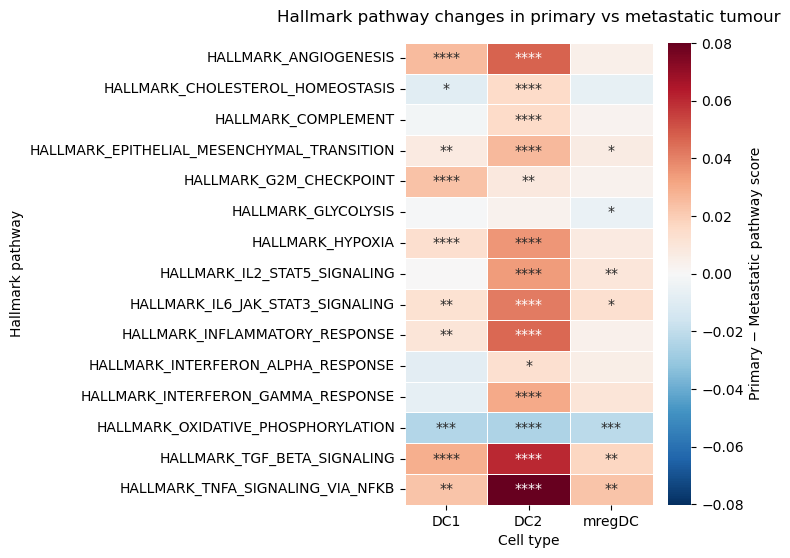

In [21]:
# Convert to matrix
heatmap_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Difference"
)

# Significance matrix
significance_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Significance"
)

# Create figure
plt.figure(
    figsize=(4, max(6, len(heatmap_data) * 0.35)
    )
)

# Make colour scale symmetric around zero
max_abs = np.nanmax(np.abs(heatmap_data.values))

ax = sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    annot=significance_data,
    fmt="",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Primary − Metastatic pathway score"
    }
)

plt.xlabel("Cell type")
plt.ylabel("Hallmark pathway")

plt.title(
    "Hallmark pathway changes in primary vs metastatic tumour",
    pad=15
)

plt.tight_layout()

plt.savefig('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment/AllDC_PrimaryvMets_HallmarkHeatmap.pdf', bbox_inches='tight')

plt.show()